# Teoría de inventarios
## Investigación de Operaciones (IDO)
**Alumna:** Itzel Patricia Flores Cruz  
**Profesor:** César  
**Fuente:** *Inventory Theory: Models, Decisions, and Economic Interpretation*, octubre de 2026.

### Objetivo
Implementar los modelos de inventarios de las notas, obtener decisiones óptimas, representar gráficamente sus costos y verificar sus resultados mediante Python. Se emplean unidades monetarias genéricas y costos anuales salvo indicación contraria.

### Índice
1. Marco matemático
2. Modelos deterministas y ventas perdidas
3. Modelos estocásticos
4. Restricciones
5–7. Ejercicios y práctica
8. Validación Monte Carlo
9. Ejercicios adicionales
10. Verificación numérica y comparación de políticas
11. Conclusión y referencia.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson, norm
from scipy.optimize import brentq, minimize
pd.options.display.float_format = "{:.4f}".format
from IPython.display import display
plt.rcParams.update({"figure.figsize": (8,4), "axes.grid": True, "grid.alpha": .2, "figure.dpi": 110})

## 1. Definiciones y marco matemático (p. 2)
Un inventario permite separar el abastecimiento del consumo. Sea $I(t)$ el stock disponible, $B(t)$ la demanda pendiente, $O(t)$ los pedidos en tránsito, $X(t)=I(t)-B(t)$ el inventario neto y $Y(t)=X(t)+O(t)$ la posición de inventario.

La política $\pi$ determina cuándo y cuánto pedir. Su objetivo de largo plazo es $J(\pi)=\limsup_{T\to\infty}E_\pi[\text{costo en }[0,T]]/T$.

Notación: $D$ demanda anual, $K$ costo fijo por pedido, $h$ costo anual de mantener una unidad, $p$ costo anual por unidad pendiente, $c$ costo de compra unitario, $Q$ lote, $T$ ciclo, $L$ plazo de entrega y $P$ tasa de producción. La demanda puede ser determinista o aleatoria; los faltantes pueden acumularse o perderse. El costo de compra $cD$ se omite solo si es independiente de la decisión.

## 2.1 EOQ clásico (pp. 3–5)
Demanda constante, entrega instantánea y sin faltantes. El inventario medio es $Q/2$ y se hacen $D/Q$ pedidos al año.
$$C(Q)=\frac{KD}{Q}+\frac{hQ}{2},\quad C'(Q)=-\frac{KD}{Q^2}+\frac h2$$
Como $C''(Q)=2KD/Q^3>0$, el mínimo es $Q^*=\sqrt{2KD/h}$ y $T=Q/D$. Si el plazo de entrega es determinista, $R=DL$ (en unidades de tiempo compatibles).
**Derivación:** $C\prime(Q)=-KD/Q^2+h/2=0$. Como $C\prime\prime(Q)=2KD/Q^3>0$, el mínimo es global. Con tiempo de entrega determinista $L$ en años, $R=DL$.

Lote: 848.5281; pedidos/año: 14.1421; ciclo (días): 21.2132
Ordenar: 2545.5844; mantener: 2545.5844; total: 5091.1688


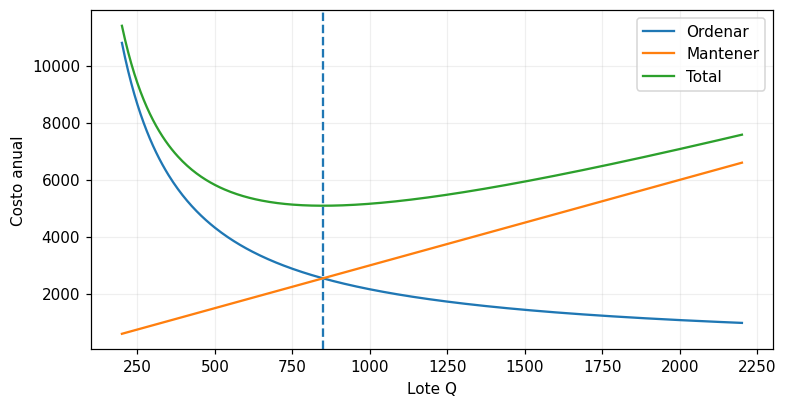

In [17]:
def costo_eoq(q,D,K,h):
    return K*D/q+h*q/2

def eoq(D,K,h):
    return np.sqrt(2*K*D/h)
D,K,h=12000,180,6
q=eoq(D,K,h)
print(f'Lote: {q:.4f}; pedidos/año: {D/q:.4f}; ciclo (días): {300*q/D:.4f}')
print(f'Ordenar: {K*D/q:.4f}; mantener: {h*q/2:.4f}; total: {costo_eoq(q,D,K,h):.4f}')
x=np.linspace(200,2200,400)
plt.plot(x,K*D/x,label='Ordenar'); plt.plot(x,h*x/2,label='Mantener'); plt.plot(x,costo_eoq(x,D,K,h),label='Total')
plt.axvline(q,ls='--'); plt.xlabel('Lote Q'); plt.ylabel('Costo anual'); plt.legend(); plt.show()

El lote recomendado es cercano a 849 unidades. En el óptimo coinciden los dos costos; duplicar la demanda multiplica el lote por la raíz de 2, no por 2.

## 2.2 Faltantes con pedidos pendientes (pp. 5–8)
Toda demanda insatisfecha se entrega posteriormente. $Q=S+B$, donde $S$ es el máximo stock y $B$ el máximo atraso.
$$C(Q,S)=\frac{KD}{Q}+\frac{hS^2+p(Q-S)^2}{2Q}$$
Al minimizar respecto a $S$, se obtiene $hS=p(Q-S)$. Sustituyendo y minimizando respecto a $Q$:
$$Q^*=\sqrt{\frac{2KD(h+p)}{hp}},\quad S^*=\frac{pQ^*}{h+p},\quad B^*=\frac{hQ^*}{h+p}.$$
**Derivación:** al fijar $Q$, $\partial C/\partial S=[hS-p(Q-S)]/Q=0$. Sustituyendo $S=pQ/(h+p)$ se obtiene $C(Q)=KD/Q+hpQ/[2(h+p)]$; su derivada determina el lote óptimo.

Q=948.6833, S=758.9466, B=189.7367, costo=4553.6798, ahorro=537.4890


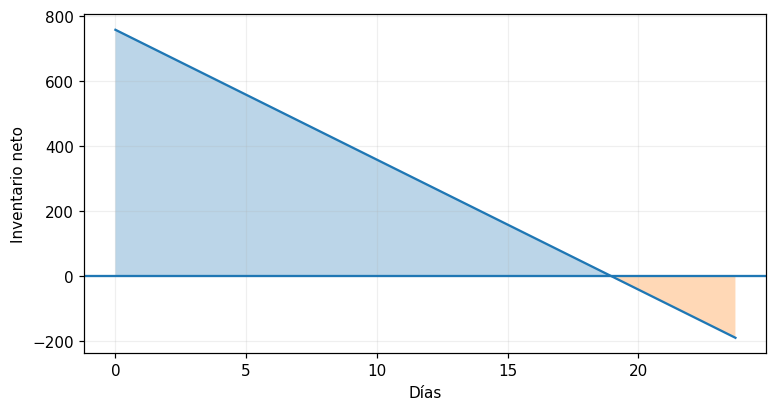

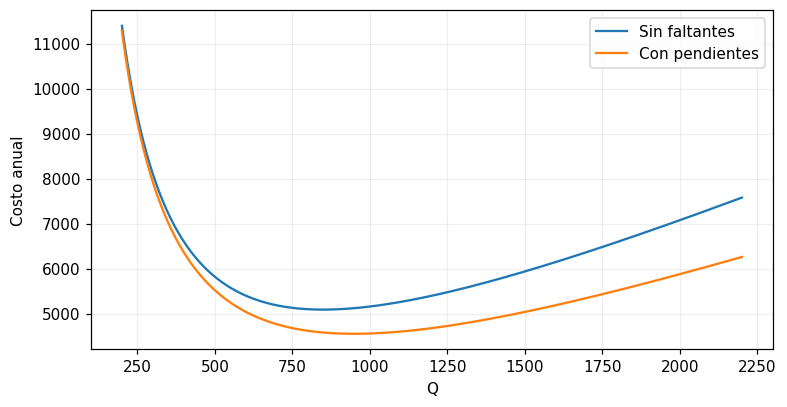

In [18]:
def backlog(D,K,h,p):
    q=np.sqrt(2*K*D*(h+p)/(h*p)); s=p*q/(h+p); b=q-s
    return q,s,b,K*D/q+(h*s*s+p*b*b)/(2*q)
p=24
qb,s,b,cb=backlog(D,K,h,p)
print(f'Q={qb:.4f}, S={s:.4f}, B={b:.4f}, costo={cb:.4f}, ahorro={costo_eoq(q,D,K,h)-cb:.4f}')
t=np.linspace(0,qb/D,300); neto=s-D*t
plt.plot(t*300,neto); plt.axhline(0); plt.fill_between(t*300,neto,0,where=neto>=0,alpha=.3); plt.fill_between(t*300,neto,0,where=neto<0,alpha=.3); plt.xlabel('Días'); plt.ylabel('Inventario neto'); plt.show()
plt.plot(x,costo_eoq(x,D,K,h),label='Sin faltantes'); plt.plot(x,K*D/x+x*h*p/(2*(h+p)),label='Con pendientes'); plt.legend(); plt.xlabel('Q'); plt.ylabel('Costo anual'); plt.show()

Se toleran cerca de 190 unidades pendientes y el atraso ocupa el 20% del ciclo. El ahorro depende de que los clientes estén dispuestos a esperar.

## 2.3 Ventas perdidas (pp. 8–11)
La demanda no atendida desaparece. Se repone hasta un nivel entero $S$ antes de cada periodo, sin costo fijo de preparación en este modelo.
$$g(S)=h_o E[(S-N)^+]+c_u E[(N-S)^+]$$
$$g(S+1)-g(S)=(h_o+c_u)F_N(S)-c_u$$
Se elige el menor entero con $F_N(S)\ge c_u/(h_o+c_u)$.
La diferencia $g(S+1)-g(S)=(h_o+c_u)F_N(S)-c_u$ cambia de signo en el cuantil óptimo.

media=22, fracción=0.8947, S=28, costo=16.8767, P(faltante)=0.0871


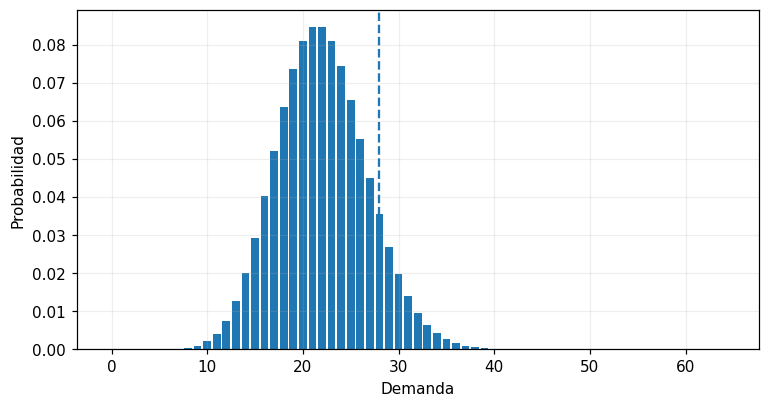

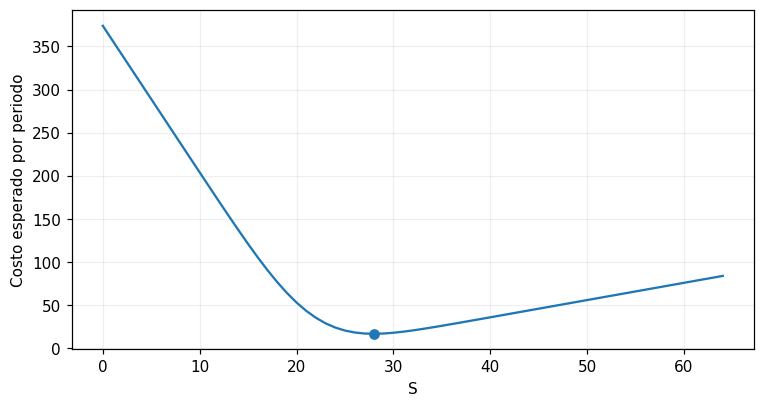

media=35, fracción=0.7826, S=40, costo=40.8897, P(faltante)=0.1751


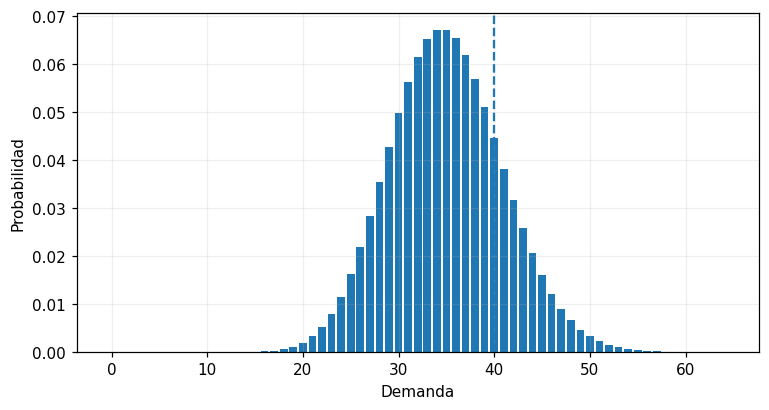

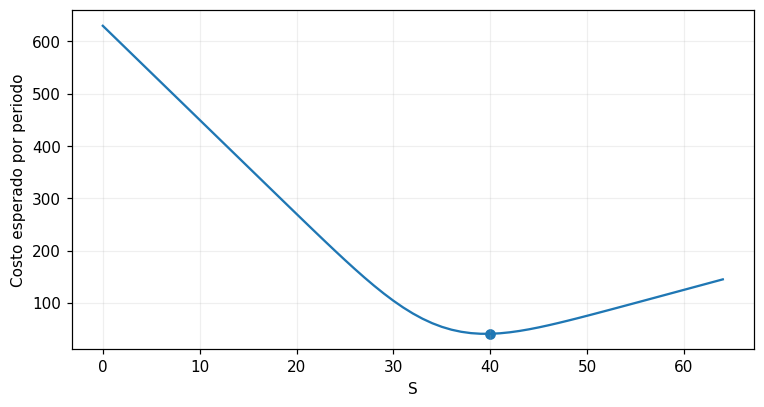

In [19]:
def perdida(s,mu,co,cu):
    k=np.arange(int(poisson.ppf(1-1e-14,mu))+1)
    return np.sum(poisson.pmf(k,mu)*(co*np.maximum(s-k,0)+cu*np.maximum(k-s,0)))
for mu,co,cu in [(22,2,17),(35,5,18)]:
    s=int(poisson.ppf(cu/(cu+co),mu))
    print(f'media={mu}, fracción={cu/(cu+co):.4f}, S={s}, costo={perdida(s,mu,co,cu):.4f}, P(faltante)={poisson.sf(s,mu):.4f}')
    k=np.arange(0,65); plt.bar(k,poisson.pmf(k,mu)); plt.axvline(s,ls='--'); plt.xlabel('Demanda'); plt.ylabel('Probabilidad'); plt.show()
    plt.plot(k,[perdida(i,mu,co,cu) for i in k]); plt.scatter(s,perdida(s,mu,co,cu)); plt.xlabel('S'); plt.ylabel('Costo esperado por periodo'); plt.show()

La fracción crítica es un umbral de probabilidad, no la proporción de unidades vendidas. La pérdida esperada y la probabilidad de agotamiento son medidas distintas.

## 2.4 Lotes enteros (pp. 11–12)
Por convexidad, basta comparar los enteros positivos adyacentes a $Q^*$: piso y techo. Para cajas completas se comparan los múltiplos factibles adyacentes.

In [20]:
def lote_entero(D,K,h,multiplo=1):
    q=eoq(D,K,h)
    candidatos=np.unique([max(multiplo,int(np.floor(q/multiplo))*multiplo),int(np.ceil(q/multiplo))*multiplo])
    costos=costo_eoq(candidatos,D,K,h)
    return pd.DataFrame({'Q':candidatos,'Costo':costos}), candidatos[np.argmin(costos)]
tabla,mejor=lote_entero(12000,180,6)
print(tabla.to_string(index=False)); print('Óptimo:',mejor)

  Q     Costo
848 5091.1698
849 5091.1696
Óptimo: 849


## 2.5 EPQ: producción a tasa finita (pp. 12–13)
Si $P>D$, el stock crece a tasa $P-D$ durante $Q/P$ años. Luego disminuye a tasa $D$.
$$I_{max}=Q(1-D/P),\quad C(Q)=KD/Q+hQ(1-D/P)/2$$
$$Q^*=\sqrt{\frac{2KD}{h(1-D/P)}}.$$

Q=979.7959, máximo=734.8469, producción=0.0204 años, ciclo=0.0816 años, costo=4409.0815


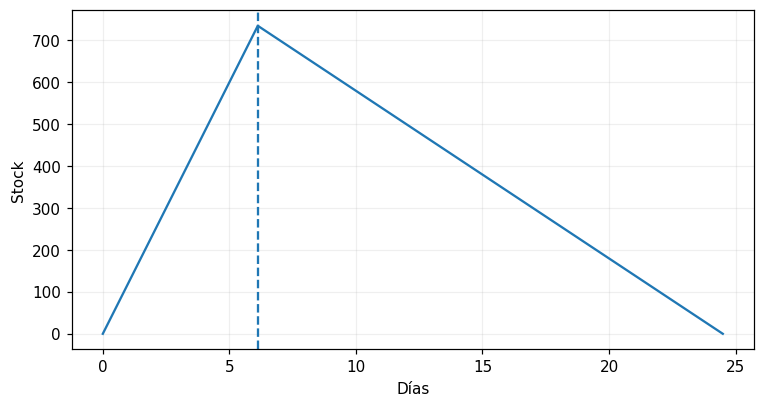

Tiempo de producción: 6.1237 días; ciclo: 24.4949 días


In [21]:
def epq(D,K,h,P):
    if P<=D: raise ValueError('Se requiere P>D')
    q=eoq(D,K,h*(1-D/P)); imax=q*(1-D/P)
    return q,imax,q/P,q/D,K*D/q+h*imax/2
qp,imax,tp,T,cp=epq(12000,180,6,48000)
print(f'Q={qp:.4f}, máximo={imax:.4f}, producción={tp:.4f} años, ciclo={T:.4f} años, costo={cp:.4f}')
plt.plot(np.array([0,tp,T])*300,[0,imax,0]); plt.axvline(tp*300,ls='--'); plt.xlabel('Días'); plt.ylabel('Stock'); plt.show()
print(f"Tiempo de producción: {300*tp:.4f} días; ciclo: {300*T:.4f} días")

La producción óptima es aproximadamente 980 unidades, pero el stock máximo es 735 porque se consume mientras se produce.

## 3.1 Modelo newsvendor (p. 14)
Se decide un pedido único antes de observar la demanda. Para costos de exceso $c_o$ y faltante $c_u$, la pérdida esperada es $G(q)=c_o E[(q-N)^+]+c_u E[(N-q)^+]$. En demanda continua, $G'(q)=(c_o+c_u)F(q)-c_u$; para demanda discreta se usa el menor entero que alcance la fracción crítica.

In [22]:
mu,co,cu=35,5,18
q_nv=int(poisson.ppf(cu/(cu+co),mu))
print('Pedido:',q_nv,'Costo:',perdida(q_nv,mu,co,cu))
print('CDF anterior:',poisson.cdf(q_nv-1,mu),'CDF óptima:',poisson.cdf(q_nv,mu))

Pedido: 40 Costo: 40.88970191456794
CDF anterior: 0.7801904451746821 CDF óptima: 0.8249380546523835


El pedido supera la media en cinco unidades porque el faltante es más costoso que el excedente. Aunque comparte la fórmula con ventas perdidas, aquí la decisión es de un solo periodo.

## 3.2 Política de revisión continua (Q,R) (pp. 14–16)
Se pide $Q$ al alcanzar la posición $R$. Con demandas diarias independientes, $\mu_L=L\mu_d$, $\sigma_L=\sigma_d\sqrt L$.
$$R=\mu_L+z_\alpha\sigma_L,\quad E[(N_L-R)^+]=\sigma_L[\phi(z)-z(1-\Phi(z))]$$
El nivel de servicio de ciclo no equivale a la tasa de surtido.

R=258.8481, R entero=259, seguridad=58.8481, faltante esperado=0.7475


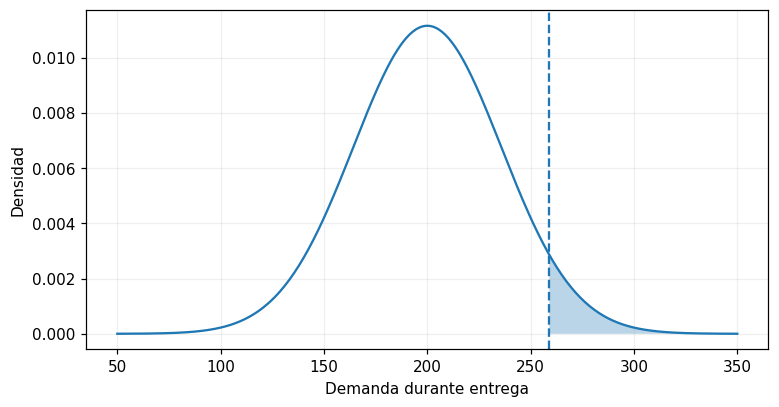

In [23]:
def reorden(mu,sd,L,alpha):
    media=L*mu; sigma=sd*np.sqrt(L); z=norm.ppf(alpha)
    return media+z*sigma, z*sigma, sigma*(norm.pdf(z)-z*norm.sf(z))
r,ss,short=reorden(40,16,5,.95)
print(f'R={r:.4f}, R entero={np.ceil(r):.0f}, seguridad={ss:.4f}, faltante esperado={short:.4f}')
k=np.linspace(50,350,400); dens=norm.pdf(k,200,16*np.sqrt(5))
plt.plot(k,dens); plt.fill_between(k,dens,where=k>=r,alpha=.3); plt.axvline(r,ls='--'); plt.xlabel('Demanda durante entrega'); plt.ylabel('Densidad'); plt.show()

Se ordena al llegar a una posición de 259 unidades. El lote EOQ puede servir de referencia, pero no demuestra que la política conjunta minimice todos los costos.

## 4. Restricciones de presupuesto y capacidad (pp. 16–19)
$$\min_{Q_i>0}\sum_i (K_iD_i/Q_i+h_iQ_i/2),\qquad \sum_i c_iQ_i\le M$$
La condición de estacionariedad del lagrangiano es $-K_iD_i/Q_i^2+h_i/2+\lambda c_i=0$. Entonces
$$Q_i(\lambda)=\sqrt{\frac{2K_iD_i}{h_i+2\lambda c_i}}.$$
Si el presupuesto no restringe, $\lambda=0$; de lo contrario se resuelve $\sum c_iQ_i=M$. Con capacidad adicional $\sum a_iQ_i\le A$, el denominador pasa a $h_i+2\lambda c_i+2\eta a_i$, con holgura complementaria para ambos multiplicadores.

     Libre  Restringido
0 848.5281     266.7913
1 692.8203     138.7632
2 547.7226     112.2985
lambda=1.3673, gasto=13000.0000, costo anual=20268.0028


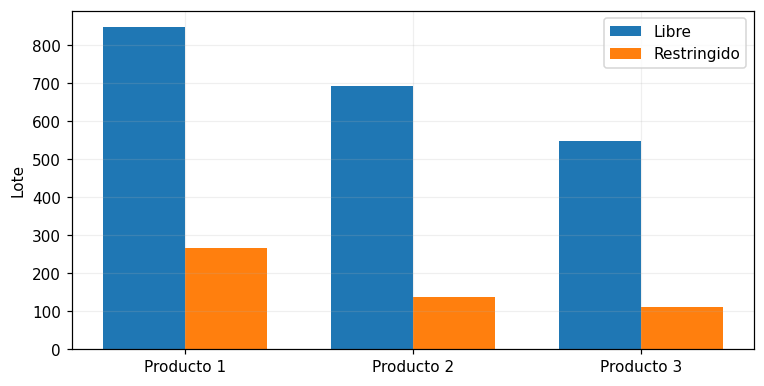

In [24]:
def presupuesto(D,K,h,c,M):
    D,K,h,c=map(lambda v:np.array(v,dtype=float),(D,K,h,c))
    def cantidades(lam): return np.sqrt(2*K*D/(h+2*lam*c))
    libre=cantidades(0); lam=0.
    if c@libre>M:
        alto=1.
        while c@cantidades(alto)>M: alto*=2
        lam=brentq(lambda z:c@cantidades(z)-M,0,alto)
    q=cantidades(lam)
    return libre,q,lam,c@q,np.sum(K*D/q+h*q/2)
libre,qr,lam,gasto,costo=presupuesto([12000,8000,5000],[180,120,90],[6,4,3],[20,35,25],13000)
print(pd.DataFrame({'Libre':libre,'Restringido':qr})); print(f'lambda={lam:.4f}, gasto={gasto:.4f}, costo anual={costo:.4f}')
i=np.arange(3); plt.bar(i-.18,libre,.36,label='Libre'); plt.bar(i+.18,qr,.36,label='Restringido'); plt.xticks(i,['Producto 1','Producto 2','Producto 3']); plt.ylabel('Lote'); plt.legend(); plt.show()

El presupuesto de 13,000 corresponde a una reposición simultánea, no al costo anual. El multiplicador expresa el beneficio marginal de ampliar ese presupuesto. Redondear los lotes por separado puede violar la restricción.

**Nota:** el ejemplo del PDF solo especifica presupuesto. El siguiente ejemplo de capacidad usa datos ilustrativos añadidos, no datos del profesor.

### 4.2 Presupuesto y capacidad simultáneos: ejemplo complementario
Se conservan los tres productos de la sección 4 y se agregan coeficientes de espacio $a=(1,2,1)$ y capacidad $A=600$ (supuestos ilustrativos). Se minimiza el costo con ambas restricciones mediante optimización convexa. Se comprueba la factibilidad y la estacionariedad KKT.

In [25]:
D4=np.array([12000.,8000.,5000.]); K4=np.array([180.,120.,90.]); h4=np.array([6.,4.,3.]); c4=np.array([20.,35.,25.]); a4=np.array([1.,2.,1.]); M4,A4=13000.,600.
# Minimizar el negativo de la función dual convexa en los multiplicadores.
def qdual(v):
    return np.sqrt(K4*D4/(h4/2+v[0]*c4+v[1]*a4))
def dual_neg(v):
    return v@[M4,A4]-2*np.sum(np.sqrt(K4*D4*(h4/2+v[0]*c4+v[1]*a4)))
def grad(v):
    return np.array([M4-c4@qdual(v), A4-a4@qdual(v)])
res=minimize(dual_neg,[1.,1.],jac=grad,bounds=[(0,None),(0,None)],method='L-BFGS-B',options={'ftol':1e-15,'gtol':1e-9})
qc=qdual(res.x)
display(pd.DataFrame({'Producto':[1,2,3],'Lote':qc}))
print('Multiplicadores:',res.x)
print(f'Presupuesto: {c4@qc:.4f}; espacio: {a4@qc:.4f}; costo anual: {np.sum(K4*D4/qc+h4*qc/2):.4f}')
assert np.all(grad(res.x)>=-1e-3)
assert np.allclose(res.x*grad(res.x),0,atol=.01)

,Producto,Lote
0,1,246.2247
1,2,119.4732
2,3,114.8289


Multiplicadores: [ 0.        32.6279335]
Presupuesto: 11976.7785; espacio: 600.0000; costo anual: 21876.4877


La capacidad y el presupuesto se evalúan por separado: una restricción puede quedar holgada. Los multiplicadores no negativos muestran el valor marginal de relajar cada límite.

## 5–7. Preguntas resueltas y práctica computacional (pp. 19–22)
Se reutilizan las funciones anteriores y se comprueban las decisiones con sus costos o condiciones de optimalidad.

In [26]:
# 1. EOQ y frecuencia
q=eoq(18000,125,5); print('1:',q,18000/q,costo_eoq(q,18000,125,5),125*18000/q,5*q/2)
# 2. Sensibilidad de faltantes
for p in [8,80]: print('2:',p,backlog(9000,100,8,p))
# 3. Cuantil Poisson y diferencias
s=int(poisson.ppf(.8,14)); print('3:',s,15*poisson.cdf(s-1,14)-12,15*poisson.cdf(s,14)-12)
# 4. Lotes enteros
q=eoq(5100,70,9); tab,mejor=lote_entero(5100,70,9); tab['Diferencia']=tab['Costo']-costo_eoq(q,5100,70,9); print('4:',tab)
# 5. Producción: Imax/Q
print('5: factor de stock máximo',1-20000/25000)
# 6. Servicio
for a in [.90,.99]: print('6:',a,reorden(30,9,8,a)[0],np.ceil(reorden(30,9,8,a)[0]))

1: 948.6832980505138 18.973665961010276 4743.416490252569 2371.7082451262845 2371.7082451262845
2: 8 (np.float64(670.820393249937), np.float64(335.4101966249685), np.float64(335.4101966249685), np.float64(2683.2815729997474))
2: 80 (np.float64(497.49371855331), np.float64(452.26701686664546), np.float64(45.22670168666451), np.float64(3618.1361349331637))
3: 17 -0.6612341744133836 0.40800928853269625
4:      Q     Costo  Diferencia
0  281 2534.9626      0.0070
1  282 2534.9574      0.0018
5: factor de stock máximo 0.19999999999999996
6: 0.9 272.62297688772566 273.0
6: 0.99 299.21914885679473 300.0


**Interpretación:** 1) Los costos de pedido y mantenimiento son iguales. 2) Mayor penalización reduce el atraso. 3) El cambio de signo de la diferencia confirma el mínimo. 4) Se compara el costo con la cota continua. 5) $I_{max}=Q/5$; con $P=D$ no se acumula stock. 6) Mayor servicio requiere más seguridad. 7) Las condiciones KKT son estacionariedad, factibilidad, $\lambda\ge0$ y $\lambda(c_1Q_1+c_2Q_2-M)=0$; al ampliar el presupuesto, disminuye el multiplicador hasta cero. 8) Cinco ventas perdidas cuestan $5\ell$, mientras cinco unidades pendientes durante dos días cuestan $10p/365$; no son cargos equivalentes.

## 8. Validación Monte Carlo (pp. 22–23)
Se simulan 200,000 demandas Poisson con semilla 2026 y se compara el costo medio con la esperanza calculada por la distribución. El error estándar mide variabilidad de simulación, no incertidumbre sobre el modelo de demanda.

Monte Carlo=16.8676, error estándar=0.0366, exacto=16.8767
IC aproximado 95%: [16.7958, 16.9394]


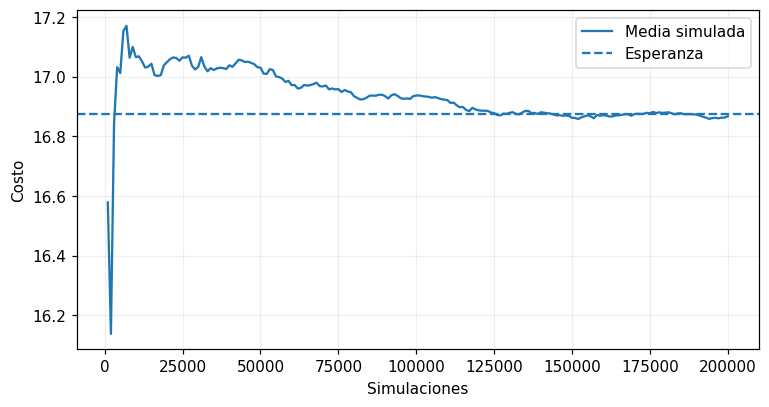

In [27]:
rng=np.random.default_rng(2026)
demanda=rng.poisson(22,200_000)
realizado=2*np.maximum(28-demanda,0)+17*np.maximum(demanda-28,0)
media=realizado.mean(); se=realizado.std(ddof=1)/np.sqrt(len(realizado)); exacto=perdida(28,22,2,17)
print(f'Monte Carlo={media:.4f}, error estándar={se:.4f}, exacto={exacto:.4f}')
print(f'IC aproximado 95%: [{media-1.96*se:.4f}, {media+1.96*se:.4f}]')
ns=np.arange(1000,len(realizado)+1,1000); plt.plot(ns,np.cumsum(realizado)[ns-1]/ns,label='Media simulada'); plt.axhline(exacto,ls='--',label='Esperanza'); plt.xlabel('Simulaciones'); plt.ylabel('Costo'); plt.legend(); plt.show()

## 9. Ejercicios adicionales del PDF (pp. 23–25)
Se resuelven los siete ejercicios con los datos originales y se verifican las restricciones.

In [28]:
# Ejercicio 1: EOQ, 360 días
q=eoq(18000,125,9); print(f'1: Q={q:.4f}, frecuencia={18000/q:.4f}, días={360*q/18000:.4f}, ordenar={125*18000/q:.4f}, mantener={9*q/2:.4f}, segunda derivada={2*125*18000/q**3:.6f}')
# Ejercicio 2: faltantes
q2,s,b,cc=backlog(18000,125,9,36); print(f'2: Q={q2:.4f}, S={s:.4f}, B={b:.4f}, días con stock={360*s/18000:.4f}, días pendientes={360*b/18000:.4f}, costo={cc:.4f}')
# Ejercicio 3: distribución discreta
n=np.arange(5); prob=np.array([.05,.15,.35,.30,.15]); cdf=np.cumsum(prob)
loss=np.array([np.sum(prob*(2*np.maximum(j-n,0)+8*np.maximum(n-j,0))) for j in n]); print(pd.DataFrame({'S':n,'CDF':cdf,'Costo':loss})); print('3: óptimo',n[np.argmin(loss)])
# Ejercicio 4: múltiplos de 50
print('4:',lote_entero(12000,180,6,50))
# Ejercicio 5: EPQ
print('5: Q, pico, duración producción, ciclo, costo',epq(10000,150,4,25000))
# Ejercicio 6: servicio
for a in [.9,.95,.99]: print('6:',a,reorden(25,8,9,a)[0],np.ceil(reorden(25,8,9,a)[0]))
# Ejercicio 7: presupuesto
libre7,q7,l7,g7,c7=presupuesto([5000,9000],[75,110],[3,5],[12,18],8000)
print('7:',libre7,q7,l7,g7,c7)
assert np.isclose(g7,8000)
print('Residuos de estacionariedad:',-np.array([75*5000,110*9000])/q7**2+np.array([3,5])/2+l7*np.array([12,18]))

1: Q=707.1068, frecuencia=25.4558, días=14.1421, ordenar=3181.9805, mantener=3181.9805, segunda derivada=0.012728
2: Q=790.5694, S=632.4555, B=158.1139, días con stock=12.6491, días pendientes=3.1623, costo=5692.0998
   S    CDF   Costo
0  0 0.0500 18.8000
1  1 0.2000 11.3000
2  2 0.5500  5.3000
3  3 0.8500  2.8000
4  4 1.0000  3.3000
3: óptimo 3
4: (     Q     Costo
0  800 5100.0000
1  850 5091.1765, np.int64(850))
5: Q, pico, duración producción, ciclo, costo (np.float64(1118.033988749895), np.float64(670.820393249937), np.float64(0.044721359549995794), np.float64(0.11180339887498948), np.float64(2683.2815729997474))
6: 0.9 255.7572375730704 256.0
6: 0.95 264.47648704683536 265.0
6: 0.99 280.8323489769802 281.0
7: [500.        629.2853089] [224.61569711 294.70064637] 0.494398023191292 7999.999999999999 6102.534508715277
Residuos de estacionariedad: [-1.77635684e-15  0.00000000e+00]


## 10. Comparación y comprobaciones independientes
Los tres modelos siguientes usan los mismos datos de demanda, preparación y almacenamiento. Sus costos no representan beneficios ni son comparables sin considerar sus diferentes compromisos de servicio.

In [29]:
d,k,h0=12000,180,6
qe=eoq(d,k,h0); qb,sb,bb,cb=backlog(d,k,h0,24); qp,ip,_,_,cp=epq(d,k,h0,48000)
resumen=pd.DataFrame({'Modelo':['EOQ','Backordering','EPQ'],'Lote':[qe,qb,qp],'Stock máximo':[qe,sb,ip],'Costo anual':[costo_eoq(qe,d,k,h0),cb,cp]})
display(resumen)
# Verificar mínimos con una malla de 20,001 cantidades.
for nombre,opt,f in [('EOQ',qe,lambda x:costo_eoq(x,d,k,h0)),('Backordering',qb,lambda x:k*d/x+h0*24*x/(2*(h0+24))),('EPQ',qp,lambda x:costo_eoq(x,d,k,h0*(1-d/48000)))]:
    rejilla=np.linspace(.4*opt,1.8*opt,20001); mejor=rejilla[np.argmin(f(rejilla))]
    assert abs(mejor-opt)/opt<.001
    print(f'{nombre}: analítico={opt:.4f}, malla={mejor:.4f}')
assert np.isclose(k*d/qe,h0*qe/2)
assert np.isclose(sb+bb,qb)
for mu,co,cu in [(22,2,17),(35,5,18),(14,3,12)]:
    S=int(poisson.ppf(cu/(cu+co),mu)); opciones=np.arange(100)
    assert S==opciones[np.argmin([perdida(j,mu,co,cu) for j in opciones])]
print('Todas las verificaciones de esta sección fueron satisfactorias.')

,Modelo,Lote,Stock máximo,Costo anual
0,EOQ,848.5281,848.5281,5091.1688
1,Backordering,948.6833,758.9466,4553.6798
2,EPQ,979.7959,734.8469,4409.0815


EOQ: analítico=848.5281, malla=848.5027
Backordering: analítico=948.6833, malla=948.6548
EPQ: analítico=979.7959, malla=979.7665
Todas las verificaciones de esta sección fueron satisfactorias.


### Sensibilidad de la decisión
Se modifica un parámetro a la vez para observar cómo cambia la política óptima. Los demás parámetros permanecen constantes.

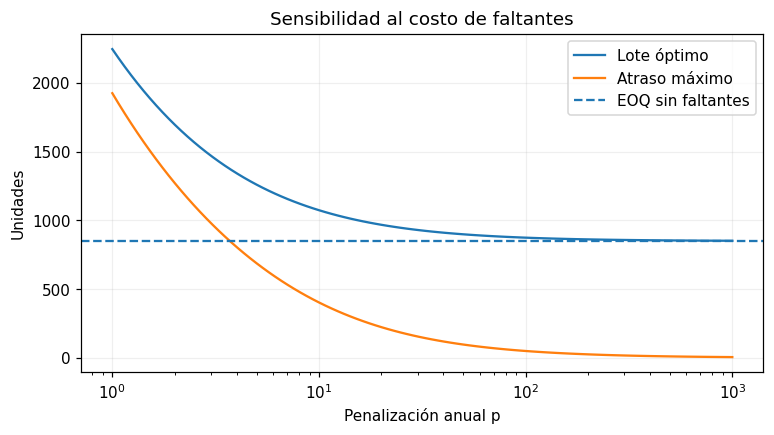

In [30]:
penalizaciones=np.geomspace(1,1000,100)
lotes=np.array([backlog(12000,180,6,p)[:3] for p in penalizaciones])
plt.semilogx(penalizaciones,lotes[:,0],label='Lote óptimo'); plt.semilogx(penalizaciones,lotes[:,2],label='Atraso máximo'); plt.axhline(eoq(12000,180,6),ls='--',label='EOQ sin faltantes'); plt.xlabel('Penalización anual p'); plt.ylabel('Unidades'); plt.title('Sensibilidad al costo de faltantes'); plt.legend(); plt.show()


Cuando la penalización aumenta, el atraso disminuye y el lote se aproxima al EOQ clásico. La gráfica confirma el comportamiento límite descrito en las notas.

## 11. Conclusión
La teoría de inventarios permite encontrar cantidades de pedido o producción que equilibran costos de preparación, almacenamiento y faltantes. La elección del modelo depende de cómo se presenta la demanda, de si los clientes esperan, del tiempo de reposición y de los recursos disponibles. Python facilita la comparación de políticas, la verificación de mínimos y la representación de los resultados. Las simulaciones complementan los cálculos analíticos, pero no sustituyen la revisión de sus supuestos.

## Referencia
*Inventory Theory: Models, Decisions, and Economic Interpretation*. Lecture Notes, octubre de 2026, pp. 1–25. Material proporcionado en Investigación de Operaciones.